In [4]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean/zomato_clean.csv")
print(df.shape)

(12376, 11)


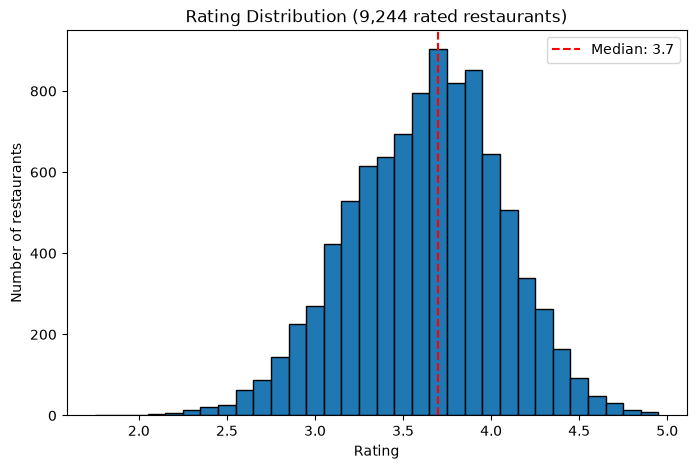

In [7]:
ratings = df["rating"].dropna()
plt.figure(figsize=(8, 5))
plt.hist(ratings, bins=np.arange(1.75, 5.05, 0.1), edgecolor="black")
plt.axvline(ratings.median(), color="red", linestyle="--", label=f"Median: {ratings.median():.1f}")
plt.title(f"Rating Distribution ({len(ratings):,} rated restaurants)")
plt.xlabel("Rating")
plt.ylabel("Number of restaurants")
plt.legend()
plt.savefig("../dashboard/rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print("Share rated 4.0 or higher:", round((ratings >= 4.0).mean() * 100, 1), "%")
print("Share rated 4.5 or higher:", round((ratings >= 4.5).mean() * 100, 1), "%")

Share rated 4.0 or higher: 22.8 %
Share rated 4.5 or higher: 2.1 %


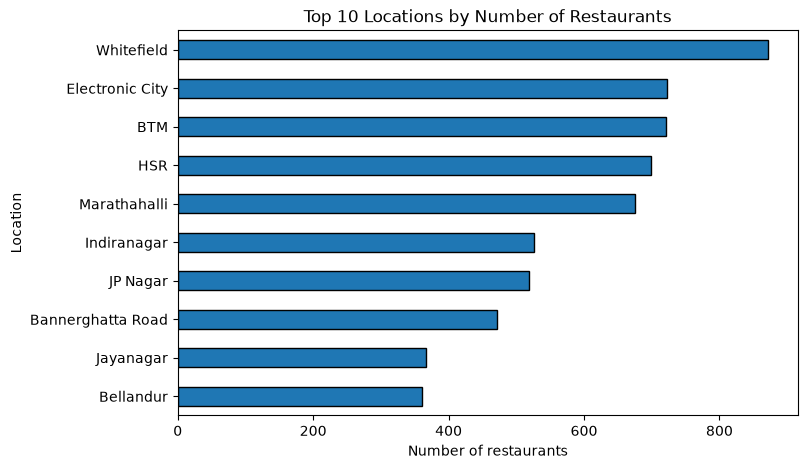

In [9]:
top_locations = df["location"].value_counts().head(10)

plt.figure(figsize=(8, 5))
top_locations.sort_values().plot(kind="barh", edgecolor="black")
plt.title("Top 10 Locations by Number of Restaurants")
plt.xlabel("Number of restaurants")
plt.ylabel("Location")
plt.savefig("../dashboard/top10_locations.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
print(top_locations)

location
Whitefield           872
Electronic City      723
BTM                  721
HSR                  699
Marathahalli         676
Indiranagar          526
JP Nagar             519
Bannerghatta Road    471
Jayanagar            366
Bellandur            360
Name: count, dtype: int64


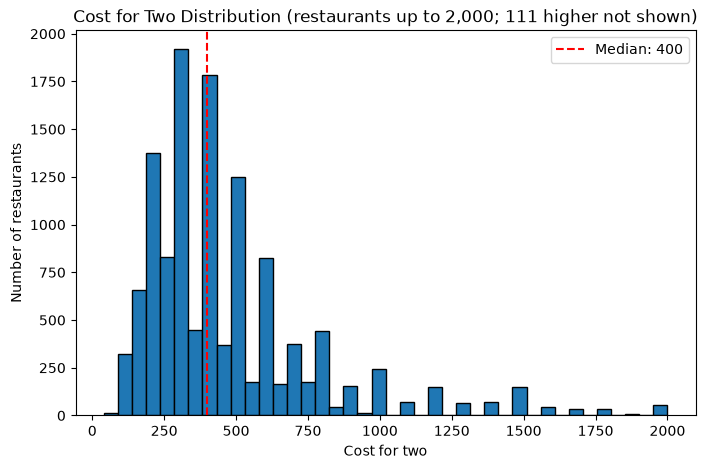

In [11]:
cost = df["cost_for_two"]
shown = cost[cost <= 2000]

plt.figure(figsize=(8, 5))
plt.hist(shown, bins=40, edgecolor="black")
plt.axvline(cost.median(), color="red", linestyle="--", label=f"Median: {cost.median():.0f}")
plt.title(f"Cost for Two Distribution (restaurants up to 2,000; {len(cost) - len(shown)} higher not shown)")
plt.xlabel("Cost for two")
plt.ylabel("Number of restaurants")
plt.legend()
plt.savefig("../dashboard/cost_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Quick chart findings
- Ratings are roughly bell-shaped, median 3.7; most restaurants fall between 3.3 and 4.1
- Whitefield has the most restaurants (~870), followed by Electronic City, BTM, HSR, and Marathahalli (each ~675 to 725)
- Median cost for two is 400; most restaurants are priced 200 to 600
- Only about 0.9% of restaurants cost more than 2,000 for two
- Restaurant counts show competition, not demand; demand is examined in the SQL step with votes and ratings